<a href="https://colab.research.google.com/github/andyotani/Machine-learning_26-27/blob/main/JS07/Tugas_Lab.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Tugas Lab

In [8]:
# Persiapan membaca dataset
# Import library
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, DBSCAN
from sklearn.neighbors import NearestNeighbors
from sklearn.metrics import silhouette_score, davies_bouldin_score

# Load dataset
df = pd.read_csv('CC_Customer_Dataset.csv')

# Inspeksi dataset
print("Ukuran dataset:", df.shape)
print("\nNama kolom:")
print(df.columns.tolist())

print("\nInformasi dataset:")
df.info()

print("\nData awal:")
print(df.head())


Ukuran dataset: (660, 7)

Nama kolom:
['Sl_No', 'Customer Key', 'Avg_Credit_Limit', 'Total_Credit_Cards', 'Total_visits_bank', 'Total_visits_online', 'Total_calls_made']

Informasi dataset:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 660 entries, 0 to 659
Data columns (total 7 columns):
 #   Column               Non-Null Count  Dtype
---  ------               --------------  -----
 0   Sl_No                660 non-null    int64
 1   Customer Key         660 non-null    int64
 2   Avg_Credit_Limit     660 non-null    int64
 3   Total_Credit_Cards   660 non-null    int64
 4   Total_visits_bank    660 non-null    int64
 5   Total_visits_online  660 non-null    int64
 6   Total_calls_made     660 non-null    int64
dtypes: int64(7)
memory usage: 36.2 KB

Data awal:
   Sl_No  Customer Key  Avg_Credit_Limit  Total_Credit_Cards  \
0      1         87073            100000                   2   
1      2         38414             50000                   3   
2      3         17341         

1. Buatlah scatterplot berdasarkan dataset menggunakan dua variabel, yaitu `Avg_Credit_Limit` dan `Total_credit_card`. Apakah sebaran data dapat dikatakan linier?

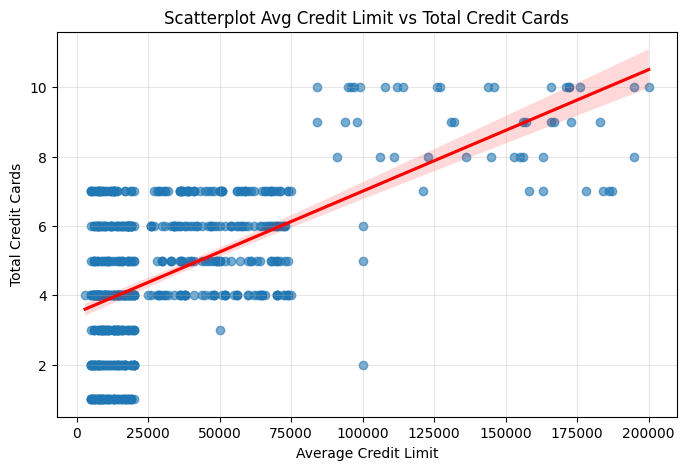

Korelasi Pearson: 0.609


In [9]:

# Scatterplot dua variabel
plt.figure(figsize=(8, 5))

sns.regplot(
    data=df,
    x='Avg_Credit_Limit',
    y='Total_Credit_Cards',
    scatter_kws={'alpha': 0.6},
    line_kws={'color': 'red'}
)

plt.title('Scatterplot Avg Credit Limit vs Total Credit Cards')
plt.xlabel('Average Credit Limit')
plt.ylabel('Total Credit Cards')
plt.grid(alpha=0.3)
plt.show()

# Menghitung korelasi Pearson
r = df['Avg_Credit_Limit'].corr(
    df['Total_Credit_Cards']
)

print(f"Korelasi Pearson: {r:.3f}")


Sebaran data menunjukkan kecenderungan hubungan positif: pelanggan dengan rata-rata limit kredit lebih tinggi cenderung memiliki lebih banyak kartu kredit. Namun, titik-titik data tidak membentuk garis lurus secara sempurna dan terlihat adanya kelompok pelanggan dengan karakteristik berbeda. Dengan demikian, hubungan kedua variabel dapat dikatakan memiliki kecenderungan linear positif sedang, tetapi tidak sepenuhnya linear.

2. Buatlah model klasterisasi dengan menggunakan model K-Means. Tentukan jumlah `k` yang terbaik dengan menggunakan elbow method. Lengkapi analisis Anda dengan linechart dan hasil analisis mengapa Anda memilih nilai tersebut.

    k      SSE
0   1  1320.00
1   2   698.29
2   3   334.72
3   4   235.39
4   5   163.47
5   6   128.96
6   7    99.37
7   8    86.53
8   9    74.53
9  10    64.83


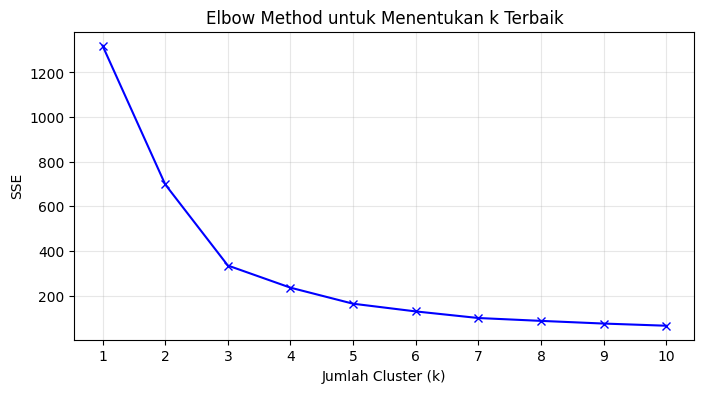

In [10]:

# Seleksi fitur
X_kmeans = df[
    ['Avg_Credit_Limit', 'Total_Credit_Cards']
]

# Standardisasi fitur
scaler_kmeans = StandardScaler()
X_kmeans_scaled = scaler_kmeans.fit_transform(X_kmeans)

# Menentukan nilai SSE untuk setiap k
sse = []
K = range(1, 11)

for k in K:
    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    kmeans.fit(X_kmeans_scaled)
    sse.append(kmeans.inertia_)

# Menampilkan hasil SSE
hasil_sse = pd.DataFrame({
    'k': list(K),
    'SSE': sse
})

print(hasil_sse.round(2))

# Membuat linechart elbow method
plt.figure(figsize=(8, 4))

plt.plot(K, sse, 'bx-')

plt.xlabel('Jumlah Cluster (k)')
plt.ylabel('SSE')
plt.title('Elbow Method untuk Menentukan k Terbaik')
plt.xticks(list(K))
plt.grid(alpha=0.3)
plt.show()



### Hasil SSE

Nilai SSE yang diperoleh dari dataset adalah sebagai berikut.

| k | SSE |
|---:|---:|
| 1 | 1320,00 |
| 2 | 698,29 |
| 3 | 334,72 |
| 4 | 235,39 |
| 5 | 163,47 |
| 6 | 128,96 |
| 7 | 99,37 |
| 8 | 86,53 |
| 9 | 74,53 |
| 10 | 64,83 |

### Analisis Elbow Method

Berdasarkan hasil SSE, jumlah cluster terbaik yang dipilih adalah $k=3$. Penurunan SSE masih cukup besar dari $k=2$ ke $k=3$, yaitu sekitar 363,57. Setelah itu, penurunannya dari $k=3$ ke $k=4$ menjadi sekitar 99,33 dan cenderung semakin stabil.

Prinsip *elbow method* adalah mencari titik ketika penurunan SSE yang awalnya tajam mulai melandai. SSE yang paling rendah tidak otomatis menunjukkan jumlah cluster terbaik karena SSE akan terus menurun ketika jumlah cluster bertambah.


Berdasarkan pola elbow pada *linechart*, $k=3$ dipilih sebagai jumlah cluster yang optimal untuk analisis K-Means menggunakan dua variabel tersebut.


3. Gambarkan hasil klasterisasi dengan model K-Means dengan menggunakan scatterplot.

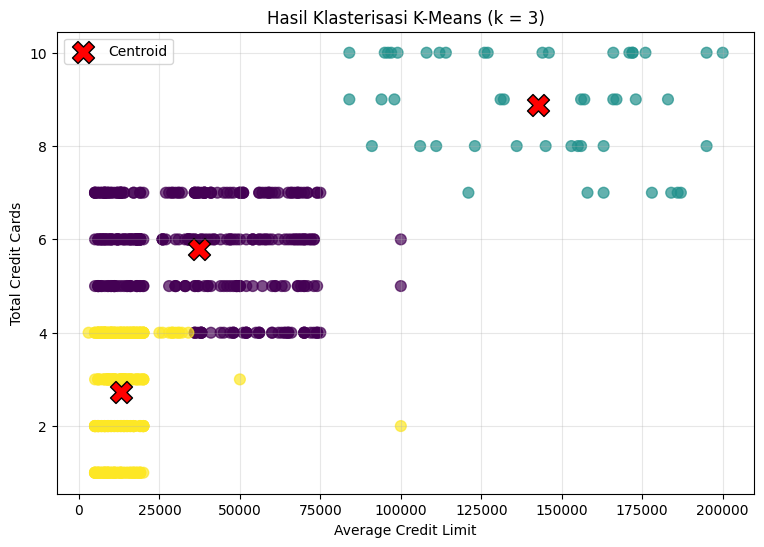

Jumlah anggota setiap cluster:
Cluster_KMeans
0    330
1     48
2    282
Name: count, dtype: int64

Centroid setiap cluster:
   Avg_Credit_Limit  Total_Credit_Cards
0          37160.61                5.79
1         142750.00                8.88
2          13134.75                2.73


In [11]:

# Membuat model K-Means dengan k = 3
kmeans_final = KMeans(
    n_clusters=3,
    random_state=42,
    n_init=10
)

cluster_kmeans = kmeans_final.fit_predict(
    X_kmeans_scaled
)

# Menyimpan label cluster
df['Cluster_KMeans'] = cluster_kmeans

# Mengembalikan centroid ke skala asli
centers = scaler_kmeans.inverse_transform(
    kmeans_final.cluster_centers_
)

# Visualisasi hasil clustering
plt.figure(figsize=(9, 6))

plt.scatter(
    df['Avg_Credit_Limit'],
    df['Total_Credit_Cards'],
    c=cluster_kmeans,
    cmap='viridis',
    s=60,
    alpha=0.7
)

# Menampilkan centroid
plt.scatter(
    centers[:, 0],
    centers[:, 1],
    marker='X',
    s=250,
    c='red',
    edgecolor='black',
    label='Centroid'
)

plt.title('Hasil Klasterisasi K-Means (k = 3)')
plt.xlabel('Average Credit Limit')
plt.ylabel('Total Credit Cards')
plt.legend()
plt.grid(alpha=0.3)
plt.show()

# Jumlah anggota setiap cluster
print("Jumlah anggota setiap cluster:")
print(df['Cluster_KMeans'].value_counts().sort_index())

# Nilai centroid dalam skala asli
centroid_df = pd.DataFrame(
    centers,
    columns=['Avg_Credit_Limit', 'Total_Credit_Cards']
)

print("\nCentroid setiap cluster:")
print(centroid_df.round(2))



### Hasil dan Interpretasi

Berdasarkan model K-Means dengan $k=3$, hasil pengelompokan pelanggan adalah sebagai berikut.

| Cluster | Jumlah Pelanggan | Rata-rata Limit Kredit | Rata-rata Jumlah Kartu |
|---:|---:|---:|---:|
| 0 | 330 | 37.160,61 | 5,79 |
| 1 | 48 | 142.750,00 | 8,88 |
| 2 | 282 | 13.134,75 | 2,73 |

Interpretasi awal dari ketiga cluster tersebut:

- **Cluster 0:** Pelanggan dengan rata-rata limit kredit menengah dan jumlah kartu relatif lebih banyak daripada Cluster 2.
- **Cluster 1:** Pelanggan dengan rata-rata limit kredit tinggi dan jumlah kartu kredit paling banyak.
- **Cluster 2:** Pelanggan dengan rata-rata limit kredit rendah dan jumlah kartu kredit relatif sedikit.

Interpretasi ini didasarkan pada dua variabel yang digunakan dalam model. Nomor cluster hanyalah label dari algoritma, bukan urutan peringkat pelanggan.

Scatterplot memperlihatkan pembagian data menjadi tiga kelompok, dengan *centroid* sebagai pusat masing-masing kelompok. Kelompok tersebut dapat digunakan untuk mengidentifikasi perbedaan karakteristik pelanggan berdasarkan limit kredit dan jumlah kartu kredit.


4. Buatlah model klasterisasi dengan menggunakan DBSCAN dengan seluruh variabel yang dapat digunakan.

Jumlah anggota setiap label DBSCAN:
Cluster_DBSCAN
-1     49
 0    605
 1      6
Name: count, dtype: int64

Jumlah cluster: 2
Jumlah noise: 49


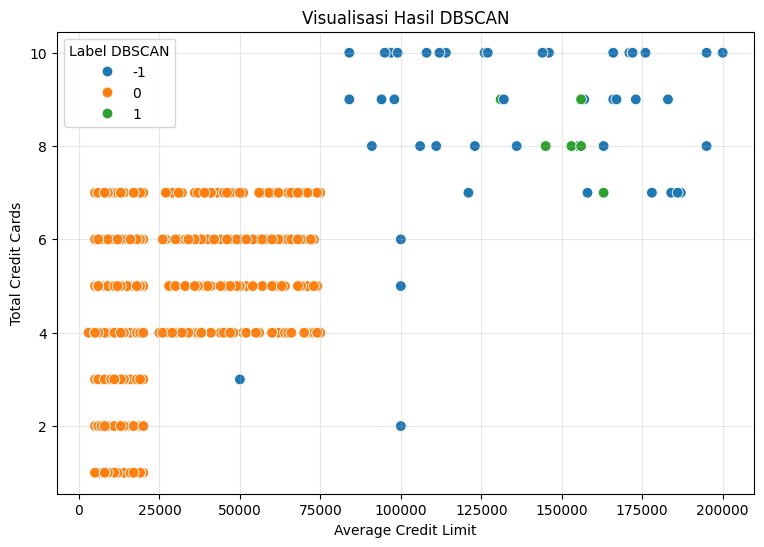

In [12]:

# Memilih seluruh fitur yang relevan
features_dbscan = [
    'Avg_Credit_Limit',
    'Total_Credit_Cards',
    'Total_visits_bank',
    'Total_visits_online',
    'Total_calls_made'
]

X_dbscan = df[features_dbscan]

# Standardisasi seluruh fitur
scaler_dbscan = StandardScaler()
X_dbscan_scaled = scaler_dbscan.fit_transform(X_dbscan)

# Membuat model DBSCAN
# Nilai eps akan diperiksa kembali pada soal nomor 5
dbscan = DBSCAN(
    eps=0.75,
    min_samples=6
)

labels_dbscan = dbscan.fit_predict(X_dbscan_scaled)

# Menyimpan hasil cluster
df['Cluster_DBSCAN'] = labels_dbscan

# Menampilkan jumlah anggota setiap cluster
print("Jumlah anggota setiap label DBSCAN:")
print(df['Cluster_DBSCAN'].value_counts().sort_index())

# Menghitung jumlah cluster dan noise
n_clusters = len(set(labels_dbscan)) - (
    1 if -1 in labels_dbscan else 0
)

n_noise = np.sum(labels_dbscan == -1)

print("\nJumlah cluster:", n_clusters)
print("Jumlah noise:", n_noise)

# Visualisasi proyeksi cluster pada dua variabel
plt.figure(figsize=(9, 6))

sns.scatterplot(
    x=df['Avg_Credit_Limit'],
    y=df['Total_Credit_Cards'],
    hue=labels_dbscan.astype(str),
    palette='tab10',
    s=60
)

plt.title('Visualisasi Hasil DBSCAN')
plt.xlabel('Average Credit Limit')
plt.ylabel('Total Credit Cards')
plt.legend(title='Label DBSCAN')
plt.grid(alpha=0.3)
plt.show()


### Hasil Awal DBSCAN

Dengan parameter `eps=0.75` dan `min_samples=6`, hasilnya adalah:

| Label | Jumlah Data | Keterangan |
|---:|---:|---|
| -1 | 49 | *Noise* atau data yang tidak masuk cluster |
| 0 | 605 | Cluster utama |
| 1 | 6 | Cluster kecil |

**Catatan:** Scatterplot di atas hanya menampilkan dua variabel sebagai proyeksi visual. Model DBSCAN sebenarnya menggunakan kelima fitur yang telah distandardisasi.

Model DBSCAN telah dibangun menggunakan lima fitur yang relevan. Hasil awal menunjukkan satu cluster utama, satu cluster kecil, dan sejumlah data yang dikategorikan sebagai *noise*. Pemilihan parameter `eps` akan diperiksa melalui grafik *k-distance* pada soal nomor 5.


5. Tentukan jumlah `k` yang terbaik dengan menggunakan elbow method. Lengkapi analisis Anda dengan linechart dan hasil analisis mengapa Anda memilih nilai tersebut.

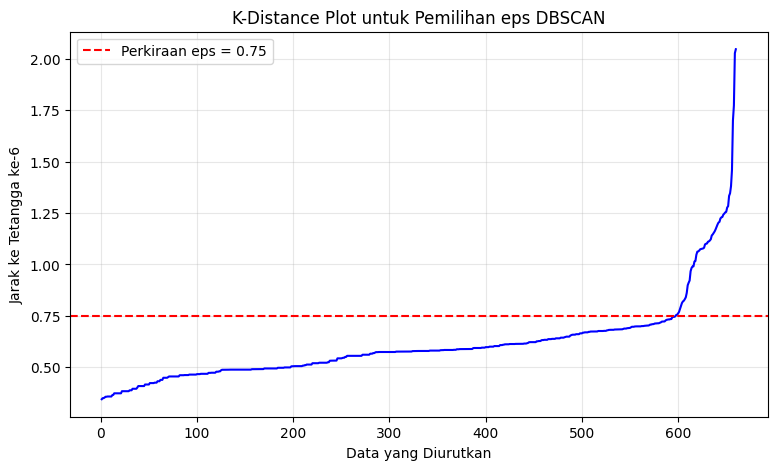

Jumlah cluster: 2
Jumlah noise: 49


In [13]:

# Menentukan min_samples
min_samples = 6

# Menghitung jarak ke tetangga ke-6
neighbors = NearestNeighbors(
    n_neighbors=min_samples
)

neighbors.fit(X_dbscan_scaled)

distances, indices = neighbors.kneighbors(
    X_dbscan_scaled
)

# Mengurutkan jarak dari kecil ke besar
k_distances = np.sort(distances[:, -1])

# Membuat k-distance plot
plt.figure(figsize=(9, 5))

plt.plot(
    range(1, len(k_distances) + 1),
    k_distances,
    color='blue'
)

# Garis perkiraan eps
plt.axhline(
    y=0.75,
    color='red',
    linestyle='--',
    label='Perkiraan eps = 0.75'
)

plt.xlabel('Data yang Diurutkan')
plt.ylabel('Jarak ke Tetangga ke-6')
plt.title('K-Distance Plot untuk Pemilihan eps DBSCAN')
plt.legend()
plt.grid(alpha=0.3)
plt.show()

# Membangun kembali model menggunakan parameter pilihan
dbscan = DBSCAN(
    eps=0.75,
    min_samples=min_samples
)

labels_dbscan = dbscan.fit_predict(X_dbscan_scaled)
df['Cluster_DBSCAN'] = labels_dbscan

print("Jumlah cluster:",
      len(set(labels_dbscan)) - (1 if -1 in labels_dbscan else 0))

print("Jumlah noise:",
      np.sum(labels_dbscan == -1))



### Analisis K-Distance Plot

Pada grafik, jarak tetangga relatif meningkat secara perlahan di sebagian besar data, kemudian menunjukkan kenaikan yang lebih tajam di bagian akhir. Titik perubahan tersebut menjadi petunjuk untuk memilih nilai `eps`.

Berdasarkan grafik dari dataset ini, nilai `eps` sekitar 0,75 dapat digunakan sebagai pilihan awal. Nilai tersebut merupakan perkiraan visual, bukan nilai optimum yang dijamin secara matematis.

Dengan parameter tersebut, DBSCAN menghasilkan dua cluster, dengan ukuran masing-masing 605 dan 6 data, serta 49 data *noise*.

Grafik *k-distance* digunakan untuk membantu memilih `eps`, sedangkan `min_samples=6` dipertahankan. Hasilnya menunjukkan bahwa DBSCAN membentuk satu cluster dominan dan satu cluster kecil. Oleh karena itu, pemilihan parameter juga perlu dievaluasi menggunakan metrik kualitas cluster, bukan hanya berdasarkan grafik.


6. Tentukan nilai silhouette score dan DBI dari model DBSCAN.

In [14]:

# Menggunakan label DBSCAN hasil soal nomor 5
labels = df['Cluster_DBSCAN'].to_numpy()

# Evaluasi seluruh label, termasuk noise (-1)
silhouette = silhouette_score(
    X_dbscan_scaled,
    labels
)

dbi = davies_bouldin_score(
    X_dbscan_scaled,
    labels
)

print("Evaluasi DBSCAN (termasuk noise)")
print(f"Silhouette Score: {silhouette:.4f}")
print(f"Davies-Bouldin Index: {dbi:.4f}")

# Evaluasi tambahan tanpa data noise
mask = labels != -1

labels_non_noise = labels[mask]
X_non_noise = X_dbscan_scaled[mask]

if len(np.unique(labels_non_noise)) >= 2:
    silhouette_non_noise = silhouette_score(
        X_non_noise,
        labels_non_noise
    )

    dbi_non_noise = davies_bouldin_score(
        X_non_noise,
        labels_non_noise
    )

    print("\nEvaluasi tanpa noise")
    print(f"Silhouette Score: {silhouette_non_noise:.4f}")
    print(f"Davies-Bouldin Index: {dbi_non_noise:.4f}")
else:
    print("\nEvaluasi tanpa noise tidak dapat dilakukan")
    print("karena jumlah cluster valid kurang dari dua.")


Evaluasi DBSCAN (termasuk noise)
Silhouette Score: 0.4697
Davies-Bouldin Index: 2.3445

Evaluasi tanpa noise
Silhouette Score: 0.5316
Davies-Bouldin Index: 0.4946



### Analisis Hasil

*Silhouette score* sebesar 0,4697 menunjukkan kualitas pemisahan yang sedang ketika seluruh label, termasuk *noise*, diperlakukan sebagai kelompok dalam perhitungan. Sementara itu, DBI sebesar 2,3445 menunjukkan bahwa kekompakan dan pemisahan kelompok belum terlalu baik menurut metrik tersebut.

Evaluasi tambahan tanpa *noise* menghasilkan *silhouette score* 0,5316 dan DBI 0,4946. Namun, angka tersebut harus ditafsirkan dengan hati-hati karena cluster yang tersisa sangat tidak seimbang: 605 data pada cluster utama dan hanya 6 data pada cluster kecil.

Perlu diingat bahwa label `-1` pada DBSCAN menandakan *noise*, bukan cluster pelanggan yang benar-benar terbentuk. Karena itu, menghitung metrik dengan memasukkan *noise* sebagai satu kelompok dapat memengaruhi interpretasi hasil.

Berdasarkan model DBSCAN dengan `eps=0.75` dan `min_samples=6`, *silhouette score* adalah 0,4697 dan DBI adalah 2,3445 apabila seluruh data, termasuk *noise*, dimasukkan ke dalam perhitungan sesuai pola evaluasi pada materi. Evaluasi tanpa *noise* juga ditampilkan sebagai informasi tambahan.



### Kesimpulan Keseluruhan

1. Scatterplot `Avg_Credit_Limit` dan `Total_Credit_Cards` menunjukkan hubungan positif sedang dengan korelasi Pearson sebesar 0,609, tetapi sebaran datanya tidak sepenuhnya linear.

2. Berdasarkan *elbow method* pada dua fitur yang telah distandardisasi, K-Means memilih jumlah cluster terbaik, yaitu $k=3$.

3. Hasil K-Means membagi pelanggan menjadi tiga kelompok berdasarkan karakteristik rata-rata limit kredit dan jumlah kartu kredit.

4. DBSCAN menggunakan lima fitur pelanggan setelah proses standardisasi, tanpa memasukkan kolom identitas.

5. *K-distance plot* digunakan untuk memperkirakan parameter `eps` DBSCAN, dengan pilihan awal `eps=0.75` dan `min_samples=6`.

6. DBSCAN menghasilkan satu cluster besar, satu cluster kecil, dan 49 data *noise*. Hasil ini menunjukkan bahwa parameter dan kesesuaian DBSCAN perlu dievaluasi lebih lanjut sebelum digunakan untuk segmentasi pelanggan.

Perlu dibedakan bahwa $k=3$ pada K-Means merupakan hasil pemilihan jumlah cluster melalui *elbow method*, sedangkan `eps=0.75` pada DBSCAN merupakan parameter jarak yang dipilih menggunakan *k-distance plot*. Keduanya memiliki fungsi yang berbeda.
